<a href="https://colab.research.google.com/github/Dylanrgyg/XAI/blob/main/WQF_7009_Assignment_1_SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Extract the uploaded ZIP project
!unzip -q -o /content/xai-series-master.zip -d /content/

# Enter the project directory
%cd /content/xai-series-master

# Display the files in the project
!ls


/content/xai-series-master
00_data_exploration.py	    02_lime.py	04_counterfactuals.py  data
01_interpretable_models.py  03_shap.py	05_lrp.py	       utils.py


In [2]:
# Install the packages required by the project
%pip install -q pandas matplotlib scikit-learn imbalanced-learn shap

(5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
col:  id


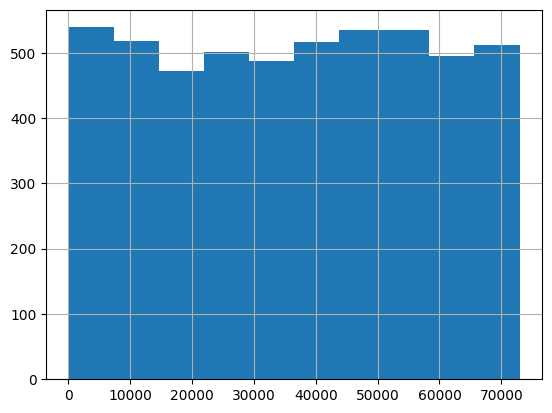

col:  gender


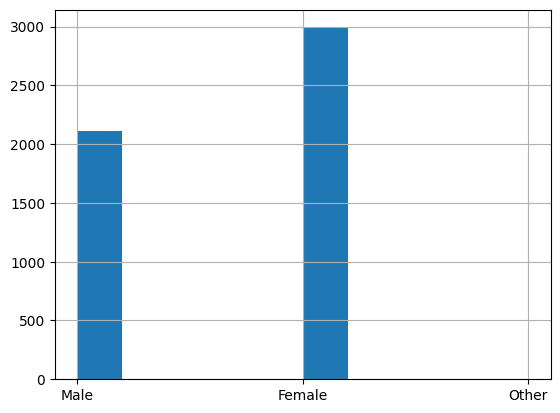

col:  age


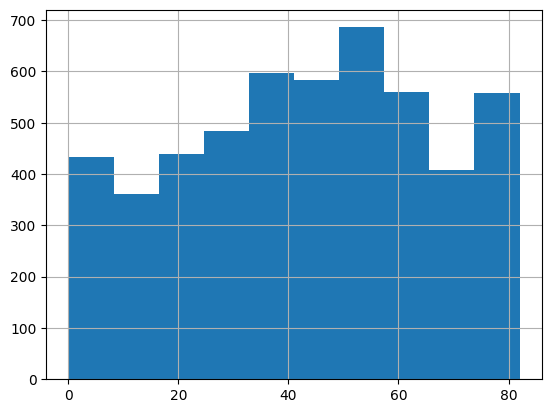

col:  hypertension


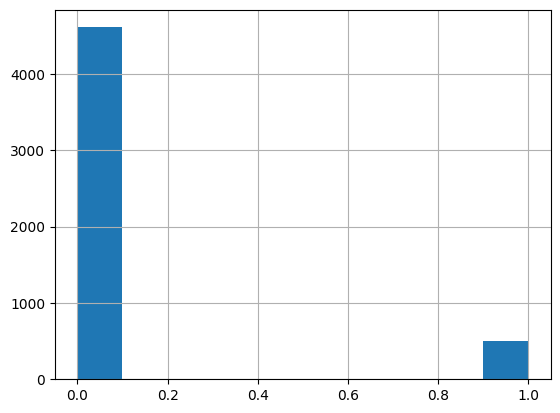

col:  heart_disease


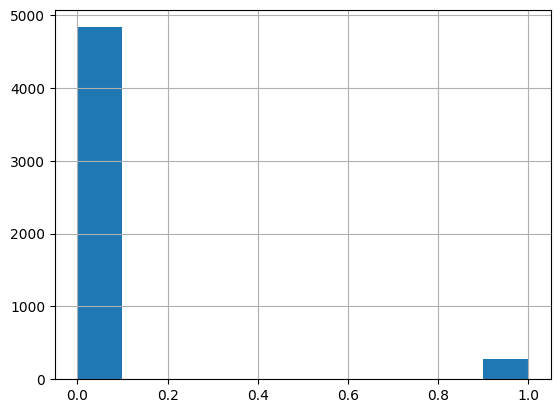

col:  ever_married


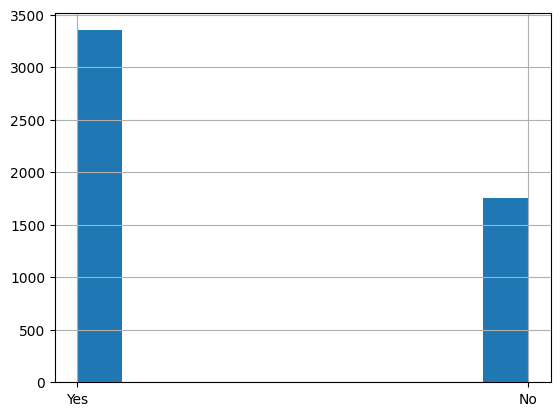

col:  work_type


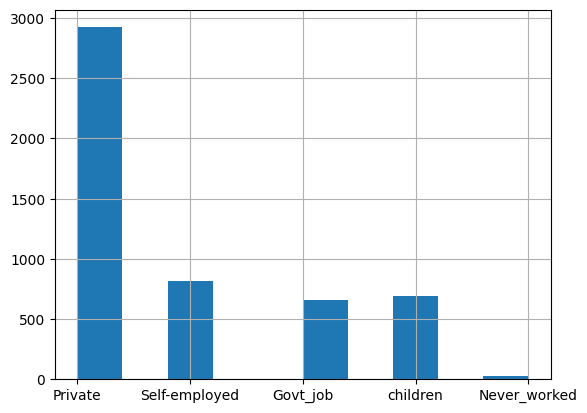

col:  Residence_type


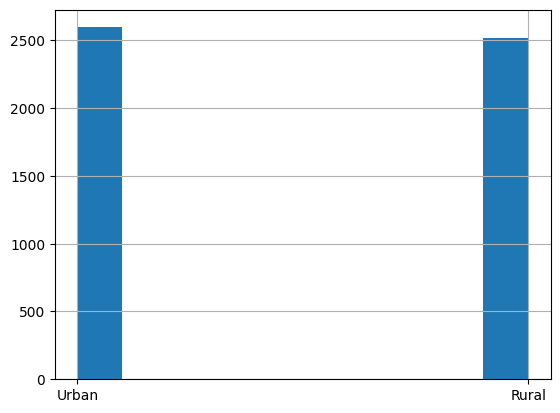

col:  avg_glucose_level


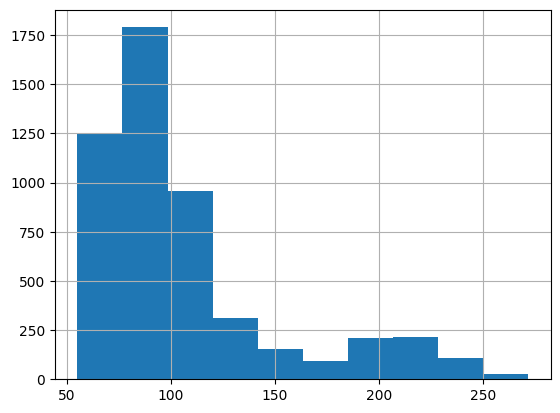

col:  bmi


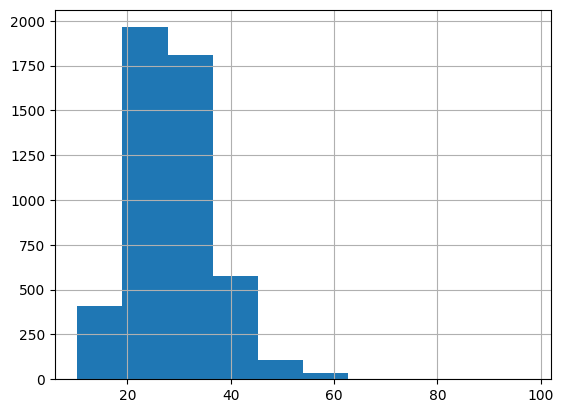

col:  smoking_status


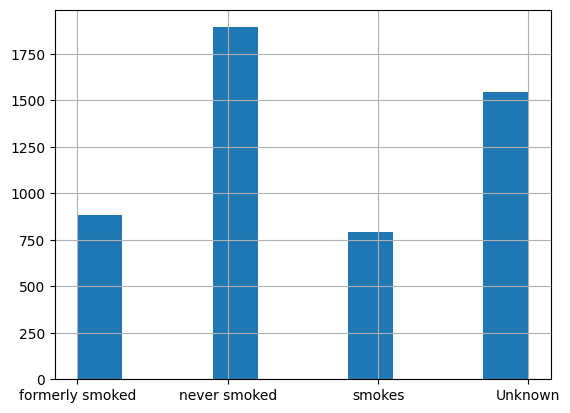

col:  stroke


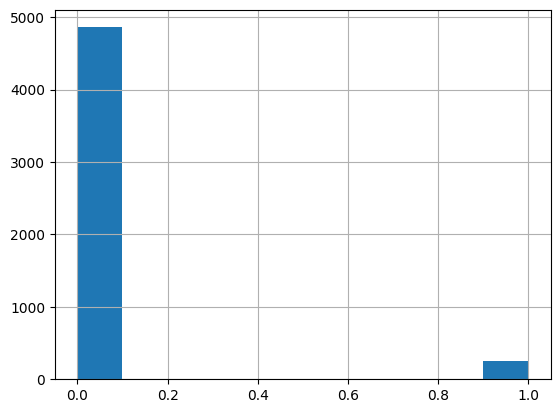

,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
0,False,True,False,False,True,False,False,True,False,False,False,True,False,True,False,False,67.0,0,1,228.69,36.6,1
1,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,61.0,0,0,202.21,0.0,1
2,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,80.0,0,1,105.92,32.5,1
3,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True,49.0,0,0,171.23,34.4,1
4,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,79.0,1,0,174.12,24.0,1


gender_Female                     0
gender_Male                       0
gender_Other                      0
ever_married_No                   0
ever_married_Yes                  0
work_type_Govt_job                0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Rural              0
Residence_type_Urban              0
smoking_status_Unknown            0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
stroke                            0
dtype: int64
stroke
0    4861
1     249
Name: count, dtype: int64


<Figure size 640x480 with 0 Axes>

In [5]:
# Task 1

# Run the original Exploratory Data Analysis script
%run 00_data_exploration.py


# Show the first five rows after preprocessing
display(data_loader.data.head())

# Check missing values after preprocessing
print(data_loader.data.isnull().sum())

# Check the distribution of the target variable
print(data_loader.data["stroke"].value_counts())

In [20]:
# Task 2
# Import required libraries
from utils import DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import shap
import matplotlib.pyplot as plt
import pandas as pd

# Load and preprocess the stroke dataset
data_loader = DataLoader()
data_loader.load_dataset()
data_loader.preprocess_data()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = data_loader.get_data_split()

# Oversample the training set to balance classes
X_train, y_train = data_loader.oversample(X_train, y_train)

# Display dataset shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("SHAP version:", shap.__version__)

Training data: (7778, 21)
Testing data: (1022, 21)
SHAP version: 0.54.1


In [38]:
from sklearn.metrics import roc_auc_score, average_precision_score
# Create a Random Forest classifier
rf = RandomForestClassifier(random_state=2021)

# Train the model using the training data
rf.fit(X_train, y_train)

# Predict stroke labels on the test data
y_pred = rf.predict(X_test)

# Evaluate the trained model
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")

# Find the index of Stroke = 1
rf_class_idx = list(rf.classes_).index(1)

# Get the predicted probabilities for Stroke = 1
rf_probabilities = rf.predict_proba(X_test)[:, rf_class_idx]

# Calculate ROC AUC
rf_roc_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

# Calculate Average Precision
rf_ap = average_precision_score(
    y_test,
    rf_probabilities
)

# Display evaluation results
print(f"Random Forest ROC AUC: {rf_roc_auc:.4f}")
print(f"Random Forest Average Precision: {rf_ap:.4f}")
print("Accuracy:", round(accuracy, 4))
print("Macro F1 Score:", round(f1, 4))
print("Model classes:", rf.classes_)

Random Forest ROC AUC: 0.7395
Random Forest Average Precision: 0.1292
Accuracy: 0.9432
Macro F1 Score: 0.5322
Model classes: [0 1]


In [9]:
# Create a SHAP TreeExplainer for the trained Random Forest
explainer = shap.TreeExplainer(rf)

# Select one test sample for initial explanation
start_index = 1
end_index = 2

X_sample = X_test.iloc[start_index:end_index]

# Calculate SHAP values for the selected sample
shap_values = explainer.shap_values(X_sample)

# Display the explainer's baseline and SHAP output shape
print("Expected values:", explainer.expected_value)
print("SHAP values type:", type(shap_values))
print("SHAP values shape:",
      np.shape(shap_values))

display(X_sample)


Expected values: [0.49925945 0.50074055]
SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (1, 21, 2)


,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,age,hypertension,heart_disease,avg_glucose_level,bmi
2813,False,True,False,False,True,False,False,True,False,False,False,True,False,False,True,False,43.0,0,0,91.13,33.9


In [10]:
# Find the output index for the stroke-positive class
class_idx = list(rf.classes_).index(1)

# Handle old and new SHAP output formats
if isinstance(shap_values, list):
    # Older SHAP versions: one array per class
    stroke_shap_values = shap_values[class_idx]
elif np.asarray(shap_values).ndim == 3:
    # Newer SHAP versions: samples x features x classes
    stroke_shap_values = shap_values[:, :, class_idx]
else:
    raise ValueError("Unexpected SHAP output shape")

# Extract the baseline for the stroke-positive class
base_value = np.asarray(
    explainer.expected_value
).reshape(-1)[class_idx]

print("Stroke class baseline:", base_value)
print("Stroke SHAP shape:", stroke_shap_values.shape)
print("Number of features:", X_sample.shape[1])


Stroke class baseline: 0.5007405502699923
Stroke SHAP shape: (1, 21)
Number of features: 21


In [11]:
# Get the model's predicted stroke probability
predicted_probability = rf.predict_proba(X_sample)[0, class_idx]

# Reconstruct the prediction using SHAP values
shap_prediction = base_value + stroke_shap_values[0].sum()

print("RF predicted probability:", predicted_probability)
print("SHAP reconstructed value:", shap_prediction)

# Verify that SHAP contributions match the model output
print("Additivity check:",
      np.isclose(predicted_probability, shap_prediction))


RF predicted probability: 0.0
SHAP reconstructed value: -3.3306690738754696e-16
Additivity check: True


In [12]:
# Task 3
# Select the same test patient used in Task 2
X_sample = X_test.iloc[1:2]

# Get the predicted class
prediction = rf.predict(X_sample)[0]

# Find the index of the stroke-positive class
class_idx = list(rf.classes_).index(1)

# Get the probability of stroke = 1
probability = rf.predict_proba(X_sample)[0, class_idx]

print("Predicted Class:", prediction)
print(f"Predicted Stroke Probability: {probability:.4f}")

# Display the patient's input features
display(X_sample)

Predicted Class: 0
Predicted Stroke Probability: 0.0000


,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,age,hypertension,heart_disease,avg_glucose_level,bmi
2813,False,True,False,False,True,False,False,True,False,False,False,True,False,False,True,False,43.0,0,0,91.13,33.9


In [13]:
# Initialize SHAP JavaScript visualization
shap.initjs()

# Generate a local Force Plot for stroke = 1
force_plot = shap.force_plot(
    base_value,
    stroke_shap_values[0],
    X_sample.iloc[0],
    matplotlib=False
)

# Display the interactive Force Plot
display(force_plot)

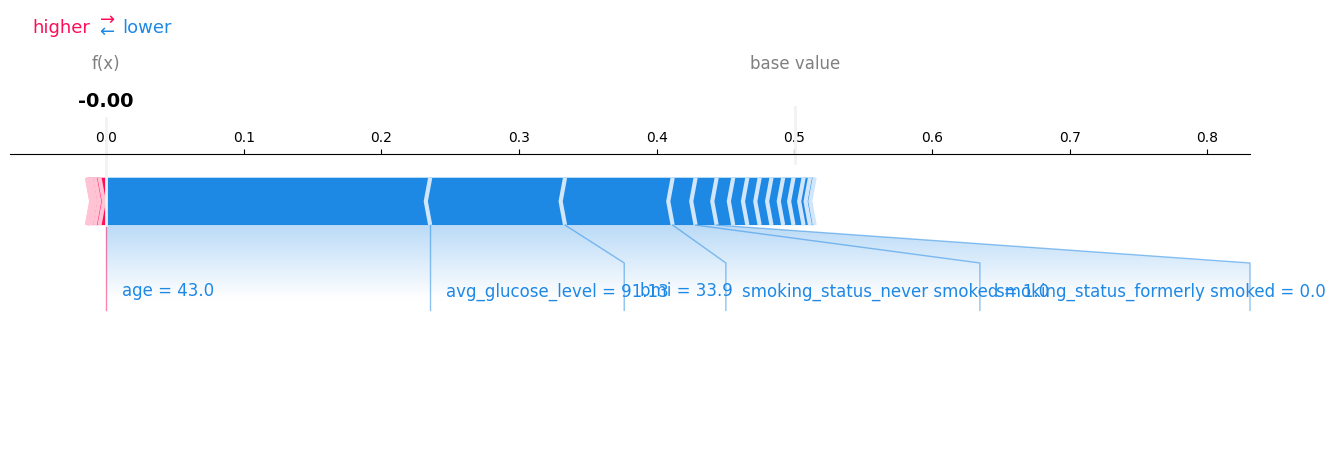

In [15]:
# Create a static SHAP Force Plot
shap.force_plot(
    base_value,
    stroke_shap_values[0],
    X_sample.iloc[0],
    matplotlib=True,
    show=False,
    figsize=(16, 4)
)

# Save the plot for the assignment presentation
plt.savefig(
    "Task3_SHAP_Force_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Create a table of SHAP contributions
local_explanation = pd.DataFrame({
    "Feature": X_sample.columns,
    "Feature Value": X_sample.iloc[0].values,
    "SHAP Value": stroke_shap_values[0]
})

# Rank features by absolute SHAP value
local_explanation["Absolute SHAP"] = np.abs(
    local_explanation["SHAP Value"]
)

local_explanation = local_explanation.sort_values(
    by="Absolute SHAP",
    ascending=False
)

# Display the ten most influential features
display(local_explanation.head(10))

,Feature,Feature Value,SHAP Value,Absolute SHAP
16,age,43.0,-0.235424,0.235424
19,avg_glucose_level,91.13,-0.097940,0.097940
20,bmi,33.9,-0.078179,0.078179
14,smoking_status_never smoked,True,-0.016673,0.016673
13,smoking_status_formerly smoked,False,-0.015294,0.015294
17,hypertension,0,-0.012032,0.012032
18,heart_disease,0,-0.010251,0.010251
0,gender_Female,False,-0.008937,0.008937
8,work_type_Self-employed,False,-0.008596,0.008596
10,Residence_type_Rural,False,-0.008473,0.008473


In [21]:
# Task 4
# Use the entire test dataset for global explanation
X_global = X_test.copy()

# Calculate SHAP values for all test patients
global_shap_values = explainer.shap_values(X_global)

# Identify the class index for Stroke = 1
class_idx = list(rf.classes_).index(1)

# Handle different SHAP versions
if isinstance(global_shap_values, list):
    # Older SHAP versions
    stroke_global_shap = global_shap_values[class_idx]

elif np.asarray(global_shap_values).ndim == 3:
    # Newer SHAP versions
    stroke_global_shap = global_shap_values[:, :, class_idx]

else:
    raise ValueError("Unexpected SHAP values format")

# Check data dimensions
print("Test samples:", X_global.shape[0])
print("Features:", X_global.shape[1])
print("SHAP shape:", stroke_global_shap.shape)

assert stroke_global_shap.shape == X_global.shape


Test samples: 1022
Features: 21
SHAP shape: (1022, 21)


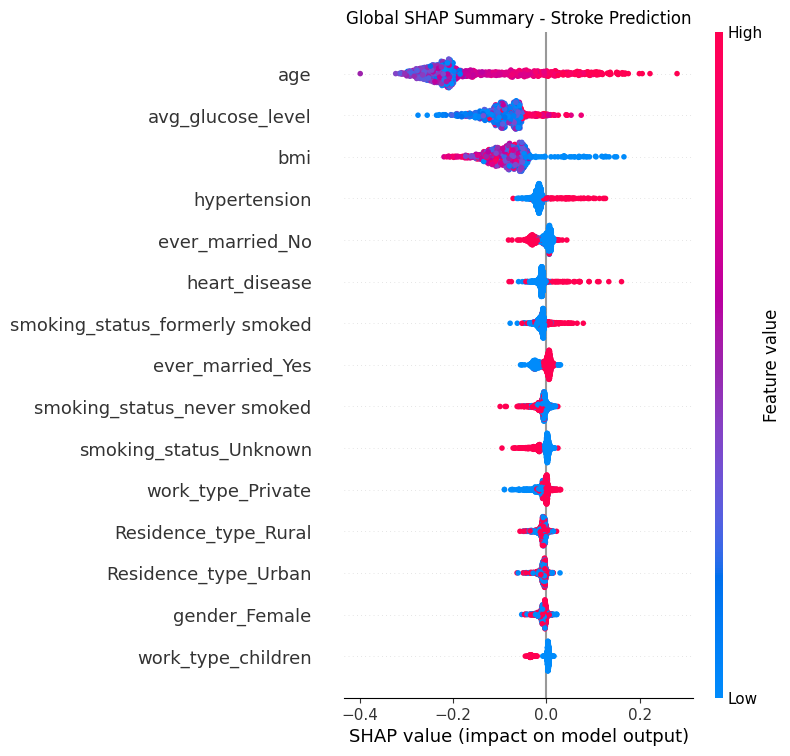

In [22]:
# Generate a SHAP Summary Plot for Stroke = 1
shap.summary_plot(
    stroke_global_shap,
    X_global,
    plot_type="dot",
    max_display=15,
    show=False
)

# Add a title
plt.title("Global SHAP Summary - Stroke Prediction")

# Save the plot
plt.savefig(
    "Task4_SHAP_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Feature,Mean Absolute SHAP
16,age,0.170596
19,avg_glucose_level,0.093032
20,bmi,0.087606
17,hypertension,0.020384
3,ever_married_No,0.013601
18,heart_disease,0.013505
13,smoking_status_formerly smoked,0.013144
4,ever_married_Yes,0.010909
14,smoking_status_never smoked,0.010621
12,smoking_status_Unknown,0.009454


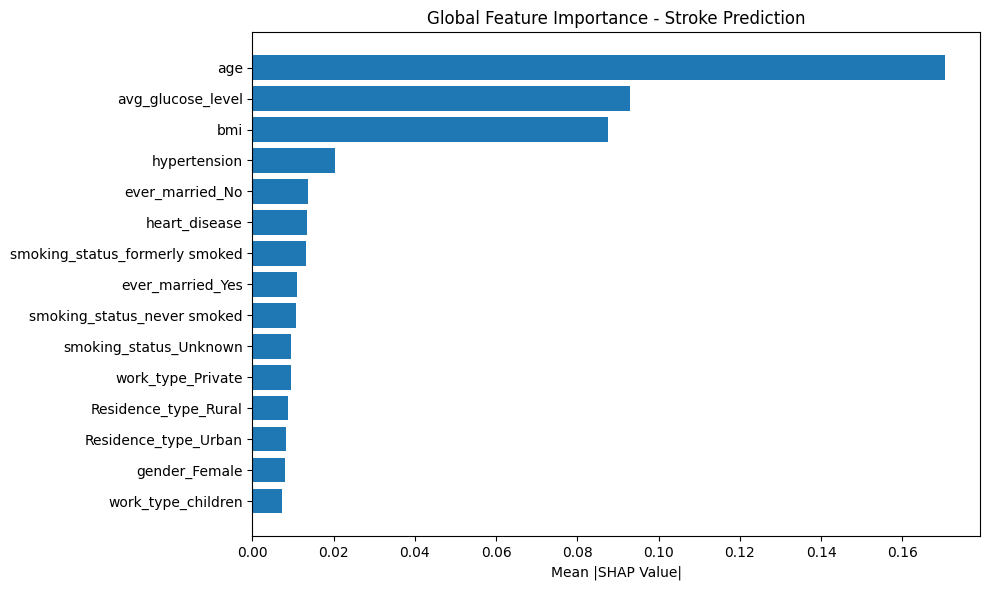

In [23]:
# Calculate Mean Absolute SHAP Value for each feature
mean_abs_shap = np.abs(stroke_global_shap).mean(axis=0)

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": X_global.columns,
    "Mean Absolute SHAP": mean_abs_shap
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
)

# Display the ten most important features
display(feature_importance.head(10))

# Plot global feature importance
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Mean Absolute SHAP"][::-1]
)

plt.xlabel("Mean |SHAP Value|")
plt.title("Global Feature Importance - Stroke Prediction")
plt.tight_layout()

# Save the figure
plt.savefig(
    "Task4_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [24]:
# Get the baseline for Stroke = 1
global_base = np.asarray(
    explainer.expected_value
).reshape(-1)[class_idx]

# Reconstruct model probabilities using SHAP
shap_probabilities = (
    global_base + stroke_global_shap.sum(axis=1)
)

# Get actual Random Forest predicted probabilities
rf_probabilities = rf.predict_proba(X_global)[:, class_idx]

# Check whether the values match
print(
    "SHAP Additivity Check:",
    np.allclose(shap_probabilities, rf_probabilities)
)

print(
    "Maximum Absolute Difference:",
    np.max(np.abs(shap_probabilities - rf_probabilities))
)

SHAP Additivity Check: True
Maximum Absolute Difference: 3.247402347028583e-15


In [25]:
# Task 6
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Confirm that previous data is available
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Check the feature names
print("Number of features:", X_train.shape[1])
print("Feature names:", X_train.columns.tolist())

# Check the labels
print("Training class distribution:")
print(pd.Series(y_train).value_counts())

print("Testing class distribution:")
print(pd.Series(y_test).value_counts())

Training shape: (7778, 21)
Testing shape: (1022, 21)
Number of features: 21
Feature names: ['gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Training class distribution:
stroke
0    3889
1    3889
Name: count, dtype: int64
Testing class distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [26]:
# Create a pipeline with feature scaling and MLP
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=500,
        random_state=2021
    ))
])

# Train the model using the existing training dataset
mlp_pipeline.fit(X_train, y_train)

# Make predictions on the test dataset
mlp_predictions = mlp_pipeline.predict(X_test)

print("MLP training completed.")

MLP training completed.


Accuracy:  0.8943
Precision: 0.1375
Recall:    0.2200
F1 Score:  0.1692

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       972
           1       0.14      0.22      0.17        50

    accuracy                           0.89      1022
   macro avg       0.55      0.57      0.56      1022
weighted avg       0.92      0.89      0.91      1022



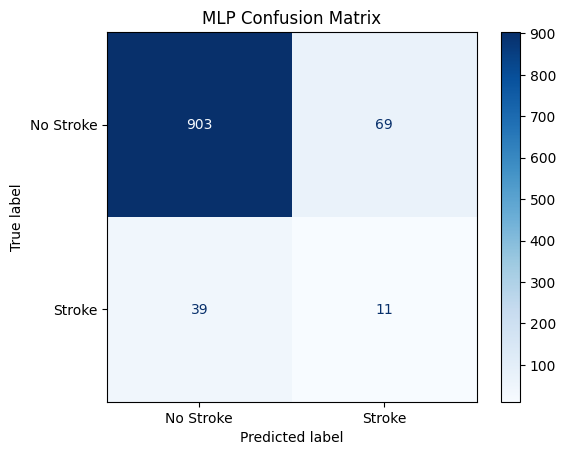

MLP ROC AUC: 0.6810
MLP Average Precision: 0.0957


In [39]:
# Evaluate the MLP model on the test set
mlp_accuracy = accuracy_score(y_test, mlp_predictions)

mlp_precision = precision_score(
    y_test, mlp_predictions, zero_division=0
)

mlp_recall = recall_score(
    y_test, mlp_predictions, zero_division=0
)

mlp_f1 = f1_score(
    y_test, mlp_predictions, zero_division=0
)

print(f"Accuracy:  {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall:    {mlp_recall:.4f}")
print(f"F1 Score:  {mlp_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, mlp_predictions,
    zero_division=0
))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    mlp_predictions,
    display_labels=["No Stroke", "Stroke"],
    cmap="Blues"
)

plt.title("MLP Confusion Matrix")
plt.show()

# Find the index of Stroke = 1
mlp_class_idx = list(
    mlp_pipeline.named_steps["mlp"].classes_
).index(1)

# Get predicted probabilities for Stroke = 1
mlp_probabilities = mlp_pipeline.predict_proba(
    X_test
)[:, mlp_class_idx]

# Calculate ROC AUC
mlp_roc_auc = roc_auc_score(
    y_test,
    mlp_probabilities
)

# Calculate Average Precision
mlp_ap = average_precision_score(
    y_test,
    mlp_probabilities
)

# Display evaluation results
print(f"MLP ROC AUC: {mlp_roc_auc:.4f}")
print(f"MLP Average Precision: {mlp_ap:.4f}")

In [28]:
# Get the index of the stroke-positive class
mlp_class_idx = list(
    mlp_pipeline.named_steps["mlp"].classes_
).index(1)

# Create a prediction function for Stroke = 1
def predict_stroke_probability(X):
    # Convert inputs to DataFrame with original feature names
    X_df = pd.DataFrame(
        X,
        columns=X_train.columns
    )

    # Return probability of the stroke-positive class
    return mlp_pipeline.predict_proba(
        X_df
    )[:, mlp_class_idx]

# Test the function
print(
    predict_stroke_probability(
        X_test.iloc[:5]
    )
)

[1.41213655e-04 1.53474789e-07 1.13927217e-26 7.23757725e-24
 4.75407850e-22]


In [29]:
# Select 40 background samples from the training data
background_data = X_train.sample(
    n=min(40, len(X_train)),
    random_state=2021
)

print("Background samples:", background_data.shape)

Background samples: (40, 21)


In [30]:
# Create Kernel SHAP Explainer
kernel_explainer = shap.KernelExplainer(
    predict_stroke_probability,
    background_data
)

# Display baseline probability
print(
    "Kernel SHAP Expected Value:",
    kernel_explainer.expected_value
)

Kernel SHAP Expected Value: 0.5228640639768958


In [31]:
# Select 10 test samples for explanation
X_kernel = X_test.iloc[:10].copy()

# Estimate Kernel SHAP values
kernel_shap_values = kernel_explainer.shap_values(
    X_kernel,
    nsamples=200,
    l1_reg="aic",
    silent=True
)

# Convert to a NumPy array
kernel_shap_values = np.asarray(kernel_shap_values)

print("Input shape:", X_kernel.shape)
print("SHAP shape:", kernel_shap_values.shape)

# Ensure one SHAP value per feature
assert kernel_shap_values.shape == X_kernel.shape

Input shape: (10, 21)
SHAP shape: (10, 21)


In [32]:
# Select the first patient
patient_idx = 0

# Get predicted stroke probability
patient_probability = predict_stroke_probability(
    X_kernel.iloc[[patient_idx]]
)[0]

print(
    f"Predicted Stroke Probability: "
    f"{patient_probability * 100:.2f}%"
)

# Initialize SHAP visualization
shap.initjs()

# Generate the Kernel SHAP Force Plot
shap.force_plot(
    kernel_explainer.expected_value,
    kernel_shap_values[patient_idx],
    X_kernel.iloc[patient_idx],
    matplotlib=False
)

Predicted Stroke Probability: 0.01%


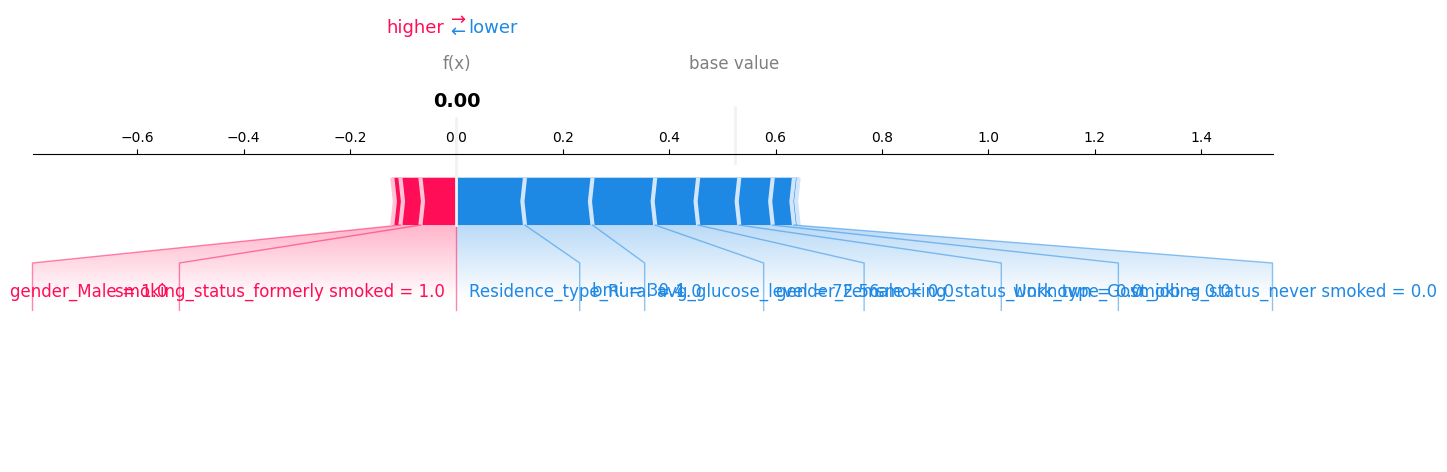

In [33]:
# Create static Kernel SHAP Force Plot
shap.force_plot(
    kernel_explainer.expected_value,
    kernel_shap_values[patient_idx],
    X_kernel.iloc[patient_idx],
    matplotlib=True,
    show=False,
    figsize=(16, 4)
)

plt.savefig(
    "Task6_Kernel_SHAP_Force.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

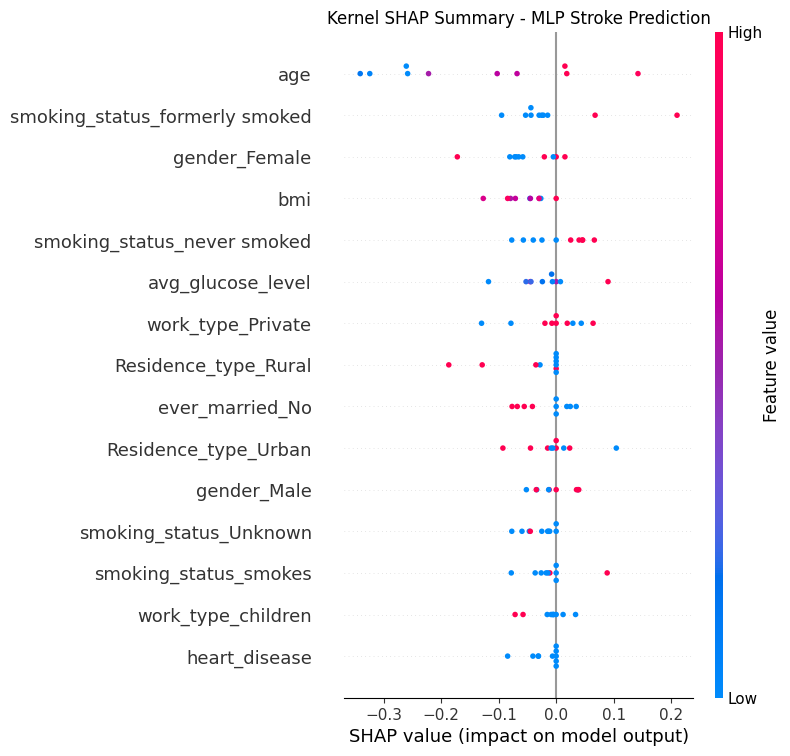

In [34]:
# Generate Kernel SHAP Summary Plot
shap.summary_plot(
    kernel_shap_values,
    X_kernel,
    plot_type="dot",
    max_display=15,
    show=False
)

plt.title("Kernel SHAP Summary - MLP Stroke Prediction")

plt.savefig(
    "Task6_Kernel_SHAP_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
# Calculate mean absolute Kernel SHAP values
kernel_importance = pd.DataFrame({
    "Feature": X_kernel.columns,
    "Mean Absolute SHAP": np.abs(
        kernel_shap_values
    ).mean(axis=0)
})

# Sort by feature importance
kernel_importance = kernel_importance.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
)

# Display the most important features
display(kernel_importance.head(10))

,Feature,Mean Absolute SHAP
16,age,0.175426
13,smoking_status_formerly smoked,0.060627
0,gender_Female,0.055891
20,bmi,0.053874
14,smoking_status_never smoked,0.042224
19,avg_glucose_level,0.039546
7,work_type_Private,0.039192
10,Residence_type_Rural,0.037928
3,ever_married_No,0.031940
11,Residence_type_Urban,0.030839


In [36]:
# Reconstruct predictions using SHAP values
base_value = float(
    np.asarray(kernel_explainer.expected_value).item()
)

reconstructed_predictions = (
    base_value + kernel_shap_values.sum(axis=1)
)

# Get original MLP predictions
original_predictions = predict_stroke_probability(
    X_kernel
)

# Compare the two results
comparison = pd.DataFrame({
    "MLP Probability": original_predictions,
    "SHAP Reconstructed": reconstructed_predictions,
    "Absolute Difference": np.abs(
        original_predictions - reconstructed_predictions
    )
})

display(comparison)

print(
    "Additivity Check:",
    np.allclose(
        original_predictions,
        reconstructed_predictions,
        atol=1e-4
    )
)

,MLP Probability,SHAP Reconstructed,Absolute Difference
0,1.412137e-04,1.412137e-04,1.273395e-16
1,1.534748e-07,1.534748e-07,5.439005e-17
2,1.139272e-26,0.000000e+00,1.139272e-26
3,7.237577e-24,0.000000e+00,7.237577e-24
4,4.754078e-22,0.000000e+00,4.754078e-22
5,3.660749e-13,3.659295e-13,1.453543e-16
6,3.681168e-04,3.681168e-04,1.479936e-17
7,1.262558e-04,1.262558e-04,2.287667e-17
8,7.566732e-06,7.566732e-06,2.288344e-17
9,9.999670e-01,9.999670e-01,0.000000e+00


Additivity Check: True


In [40]:
# Create the final model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "MLPClassifier"
    ],
    "Explainer": [
        "Tree SHAP",
        "Kernel SHAP"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf.predict(X_test)),
        mlp_accuracy
    ],
    "Precision (Stroke=1)": [
        precision_score(
            y_test, rf.predict(X_test), zero_division=0
        ),
        mlp_precision
    ],
    "Recall (Stroke=1)": [
        recall_score(
            y_test, rf.predict(X_test), zero_division=0
        ),
        mlp_recall
    ],
    "F1 (Stroke=1)": [
        f1_score(
            y_test, rf.predict(X_test), zero_division=0
        ),
        mlp_f1
    ],
    "ROC AUC": [
        rf_roc_auc,
        mlp_roc_auc
    ],
    "Average Precision": [
        rf_ap,
        mlp_ap
    ]
})

# Display the completed comparison table
display(model_comparison.round(4))

# Export the results for the assignment report
model_comparison.to_csv(
    "Task6_Final_Model_Comparison.csv",
    index=False
)

,Model,Explainer,Accuracy,Precision (Stroke=1),Recall (Stroke=1),F1 (Stroke=1),ROC AUC,Average Precision
0,Random Forest,Tree SHAP,0.9432,0.2143,0.06,0.0938,0.7395,0.1292
1,MLPClassifier,Kernel SHAP,0.8943,0.1375,0.22,0.1692,0.6810,0.0957
